<a href="https://colab.research.google.com/github/gokulvasan1011/AIML-ASSIGNMENT/blob/main/LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

(50000, 2)
sentiment
positive    25000
negative    25000
Name: count, dtype: int64
Train: 40000 | Test: 10000
X_train shape: (40000, 250) | X_test shape: (10000, 250)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 250, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,667,137 (10.17 MB)

 Trainable params: 2,667,137 (10.17 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 260s 904ms/step - accuracy: 0.7841 - loss: 0.4485 - val_accuracy: 0.8565 - val_loss: 0.3337
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 249s 883ms/step - accuracy: 0.9050 - loss: 0.2501 - val_accuracy: 0.8687 - val_loss: 0.3350
Epoch 3/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 250s 887ms/step - accuracy: 0.9339 - loss: 0.1839 - val_accuracy: 0.8800 - val_loss: 0.3256
Epoch 4/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 250s 887ms/step - accuracy: 0.9510 - loss: 0.1422 - val_accuracy: 0.8748 - val_loss: 0.3548
Epoch 5/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 265s 898ms/step - accuracy: 0.9628 - loss: 0.1086 - val_accuracy: 0.8622 - val_loss: 0.4445

Test Accuracy: 0.8831 | Test Loss: 0.3184
313/313 ━━━━━━━━━━━━━━━━━━━━ 21s 66ms/step

Classification Report:
               precision    recall  f1-score   support

    Negative       0.90      0.87      0.88      5000
    Positive       0.87      0.90      0.89      5000

    accuracy                           0.88     10000
   macro av

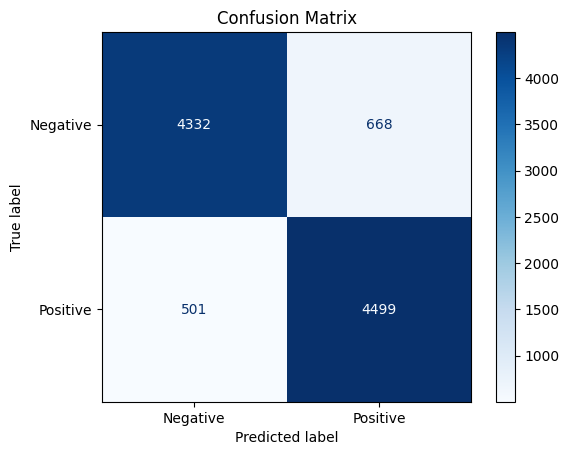

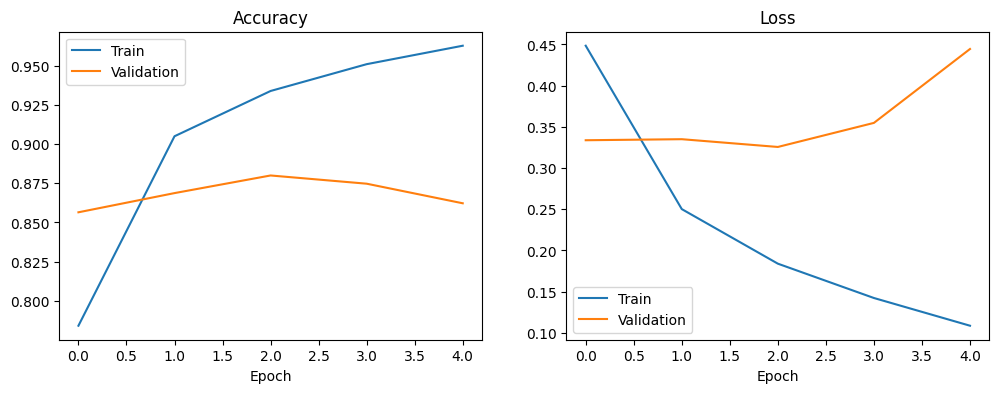

('Positive', 0.8677730560302734)
('Negative', 0.0043829502537846565)


In [ ]:
# ============================================================
# IMDB Sentiment Analysis with BiLSTM  (Google Colab)
# ============================================================
import re, zipfile, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# ------------------------------------------------------------
# 1. Upload & extract dataset
# ------------------------------------------------------------
# Check if CSV is already present directly in the environment
if os.path.exists("IMDB Dataset.csv"):
    df = pd.read_csv("IMDB Dataset.csv")
elif os.path.exists("IMDB Dataset (1).csv"):
    df = pd.read_csv("IMDB Dataset (1).csv")
else:
    from google.colab import files
    if not os.path.exists("IMDB_Dataset_csv.zip"):
        uploaded = files.upload()          # choose IMDB_Dataset_csv.zip or the CSV

    # If the user uploaded a zip, extract it; otherwise handle the raw CSV
    if os.path.exists("IMDB_Dataset_csv.zip"):
        with zipfile.ZipFile("IMDB_Dataset_csv.zip", "r") as z:
            z.extractall("imdb_data")
        df = pd.read_csv("imdb_data/IMDB Dataset.csv")
    elif any(f.startswith("IMDB Dataset") for f in os.listdir(".")):
        csv_file = [f for f in os.listdir(".") if f.startswith("IMDB Dataset")][0]
        df = pd.read_csv(csv_file)
    else:
        raise FileNotFoundError("Could not find the IMDB dataset file.")

print(df.shape)
print(df["sentiment"].value_counts())
df.head()

# ------------------------------------------------------------
# 2. Text preprocessing
# ------------------------------------------------------------
def clean_text(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)          # remove HTML tags (<br />)
    text = re.sub(r"[^a-z\s']", " ", text)      # keep letters only
    text = re.sub(r"\s+", " ", text).strip()    # collapse whitespace
    return text

df["clean_review"] = df["review"].apply(clean_text)
df["label"] = df["sentiment"].map({"positive": 1, "negative": 0})

# ------------------------------------------------------------
# 3. Train / test split  (80% / 20%)
# ------------------------------------------------------------
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["clean_review"].values,
    df["label"].values,
    test_size=0.20,
    random_state=42,
    stratify=df["label"].values
)
print("Train:", len(X_train_text), "| Test:", len(X_test_text))

# ------------------------------------------------------------
# 4. Tokenizer  (fit ONLY on training data to avoid leakage)
# ------------------------------------------------------------
VOCAB_SIZE = 20000
MAX_LEN    = 250
EMBED_DIM  = 128

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_text)

# ------------------------------------------------------------
# 5. Sequence padding
# ------------------------------------------------------------
X_train = pad_sequences(tokenizer.texts_to_sequences(X_train_text),
                        maxlen=MAX_LEN, padding="post", truncating="post")
X_test  = pad_sequences(tokenizer.texts_to_sequences(X_test_text),
                        maxlen=MAX_LEN, padding="post", truncating="post")
print("X_train shape:", X_train.shape, "| X_test shape:", X_test.shape)

# ------------------------------------------------------------
# 6. Build BiLSTM model
#    Embedding(128) -> Bidirectional LSTM (forward + backward, concatenated)
#    -> Dropout(0.5) -> Dense(64) -> Dense(1, sigmoid)
# ------------------------------------------------------------
model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM, input_length=MAX_LEN),
    Bidirectional(LSTM(64), merge_mode="concat"),   # forward + backward concatenated
    Dropout(0.5),
    Dense(64, activation="relu"),
    Dense(1, activation="sigmoid")                  # 0 = Negative, 1 = Positive
])

model.build(input_shape=(None, MAX_LEN))
model.compile(optimizer="adam",
              loss="binary_crossentropy",
              metrics=["accuracy"])
model.summary()

# ------------------------------------------------------------
# 7. Train
# ------------------------------------------------------------
callbacks = [
    EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
    ModelCheckpoint("best_bilstm.keras", monitor="val_loss", save_best_only=True)
]

history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,     # 10% of the training set used for validation
    callbacks=callbacks,
    verbose=1
)

# ------------------------------------------------------------
# 8. Evaluate on the 20% test set
# ------------------------------------------------------------
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest Accuracy: {test_acc:.4f} | Test Loss: {test_loss:.4f}")

y_pred = (model.predict(X_test) > 0.5).astype(int).ravel()
print("\nClassification Report:\n",
      classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"]).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# ------------------------------------------------------------
# 9. Training curves
# ------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="Train")
ax[0].plot(history.history["val_accuracy"], label="Validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history.history["loss"], label="Train")
ax[1].plot(history.history["val_loss"], label="Validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.show()

# ------------------------------------------------------------
# 10. Predict on custom reviews
# ------------------------------------------------------------
def predict_sentiment(text):
    seq = pad_sequences(tokenizer.texts_to_sequences([clean_text(text)]),
                        maxlen=MAX_LEN, padding="post", truncating="post")
    prob = model.predict(seq, verbose=0)[0][0]
    label = "Positive" if prob > 0.5 else "Negative"
    return label, float(prob)

print(predict_sentiment("This movie was absolutely fantastic, I loved every minute!"))
print(predict_sentiment("Terrible plot, bad acting, a complete waste of time."))